# Chapter 97: Marxian, Sraffian, and Class-Based Distribution

This notebook reruns four worked examples from the chapter: necessary and surplus hours, the one-good wage-profit frontier, prices of production with a wage gap, and composition against exploitation. Every number is the chapter's hypothetical value accounting, not an estimate; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def surplus_value(m, L, wage, c=0.0):
    """Marxian day: h = wage / m, v = m h, s = m (L - h), s / v = (L - h) / h.

    surplus-value-and-exploitation (chapter 97): m = 30, L = 8, wage 120 give h = 4, s = 120,
    s / v = 100 percent, batch value 300 + 240 = 540; L = 10 gives s = 180, 150 percent;
    wage 90 gives h = 3, s = 150, 166.7 percent.
    """
    h = wage / m
    s = m * (L - h)
    return {"h": h, "v": wage, "s": s, "new_value": m * L, "rate": s / wage, "value": c + m * L}


def wage_profit_frontier(output, inp, labor, w):
    """One-good Sraffa system output = (1 + r) input + labor w; profit = output - input - labor w, r = profit / input.

    sraffian-wage-profit-frontier (chapter 97): 100 = (1 + r) 50 + 100 w. w = 0.20 gives profit 30,
    r = 60 percent; w = 0.35 gives 30 percent; w = 0.50 gives 0; w = 0 gives 100 percent. With input 40
    and w = 0.35, profit 25 and r = 62.5 percent. R is the maximum rate at a zero wage.
    """
    profit = output - inp - labor * w
    return {"wages": labor * w, "profit": profit, "r": profit / inp, "R": (output - inp) / inp,
            "w_max": (output - inp) / labor}


def production_prices(c, v, s):
    """Prices of production p_i = c_i + v_i + r K_i with K_i = c_i + v_i and r = sum s / sum K.

    unequal-exchange (chapter 97): c = (40, 40), v = (10, 30), s = (40, 20) give r = 60 / 120 = 0.5,
    p = (75, 105), exchange ratio 1.4, values 90 each; v = (30, 30) gives r = 40 / 140 and p = (90, 90).
    """
    K = [ci + vi for ci, vi in zip(c, v)]
    r = sum(s) / sum(K)
    p = [k * (1.0 + r) for k in K]
    values = [ci + vi + si for ci, vi, si in zip(c, v, s)]
    return {"K": K, "r": r, "p": p, "values": values, "ratio": p[1] / p[0]}


def profit_rate_composition(c, v, s):
    """r = s / (c + v) = e / (k + 1) with e = s / v and k = c / v.

    tendency-of-the-rate-of-profit-to-fall (chapter 97): (80, 20, 20) gives k = 4, e = 1, r = 20 percent;
    (135, 15, 30) gives k = 9, e = 2, r = 20 percent; s = 24 gives 16 percent; c = 105 gives 25 percent.
    """
    return {"k": c / v, "e": s / v, "r": s / (c + v)}


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(surplus_value=surplus_value, wage_profit_frontier=wage_profit_frontier, production_prices=production_prices, profit_rate_composition=profit_rate_composition)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'surplus-value-and-exploitation': {'m': 30,
                                    'L': 8,
                                    'wage': 120,
                                    'h': 4,
                                    's': 120,
                                    'rate': 1.0,
                                    'c': 300,
                                    'value': 540,
                                    'L_long': 10,
                                    's_long': 180,
                                    'rate_long': 1.5,
                                    'wage_low': 90,
                                    'h_low': 3,
                                    's_low': 150,
                                    'rate_low_pct': 166.7},
 'sraffian-wage-profit-frontier': {'output': 100,
                                   'input': 50,
                                   'labor': 100,
                                   'w': 0.2,
                                   'profit': 30,
                                   'r': 0.6,
                                   'w_mid': 0.35,
                                   'r_mid': 0.3,
                                   'w_max': 0.5,
                                   'R': 1.0,
                                   'input_new': 40,
                                   'profit_new': 25,
                                   'r_new': 0.625},
 'unequal-exchange': {'c': 40,
                      'vL': 10,
                      'vH': 30,
                      'new_value': 50,
                      'sL': 40,
                      'sH': 20,
                      'value': 90,
                      'r': 0.5,
                      'pL': 75,
                      'pH': 105,
                      'ratio': 1.4,
                      'vL_equal': 30,
                      'r_equal_pct': 28.6,
                      'p_equal': 90},
 'tendency-of-the-rate-of-profit-to-fall': {'base': [80, 20, 20],
                                            'k_base': 4,
                                            'e_base': 1,
                                            'r_base': 0.2,
                                            'auto': [135, 15, 30],
                                            'k': 9,
                                            'e': 2,
                                            'r': 0.2,
                                            's_low': 24,
                                            'r_low': 0.16,
                                            'c_cheap': 105,
                                            'r_cheap': 0.25},
 'constructed': {'surplus-value-and-exploitation': {'L': [12]},
                 'unequal-exchange': {'vL': [20]},
                 'tendency-of-the-rate-of-profit-to-fall': {'c': [165]}}}


LABEL = "Hypothetical value accounting, not estimates."


def surplus_picture(day=8, wage=120):
    b = BV["surplus-value-and-exploitation"]
    m, c = b["m"], b["c"]
    r = macro.surplus_value(m, day, wage, c)
    h, s = r["h"], r["s"]
    fig, ax = new_figure()
    ax.barh([0], [h], color=PALETTE["teal"], height=0.5)
    ax.barh([0], [day - h], left=[h], color=PALETTE["gold"], height=0.5)
    label(ax, h / 2, 0, f"necessary {num(h, 0)} h", dx=0, dy=0, ha="center",
          va="center")
    label(ax, h + (day - h) / 2, 0, f"surplus {num(day - h, 0)} h", dx=0, dy=0, ha="center", va="center")
    label(ax, day, 0.25, f"s / v = {pct(r['rate'])}", col="navy", dx=0, dy=12, ha="right")
    ax.set_xlim(0, 12.5)
    ax.set_ylim(-0.8, 1.0)
    ax.set_yticks([])
    ax.set_ylabel("Working day")
    ax.set_xlabel("Hours of the working day")
    metrics = {"Necessary hours h": num(h, 0), "Wage v ($)": num(wage, 0), "Surplus s ($)": num(s, 0),
               "Rate s / v": pct(r["rate"]), "Batch value c + v + s ($)": num(r["value"], 0)}
    steps = [f"h = {wage} / {m} = {num(h, 0)} hours",
             f"s = {m} x ({day} - {num(h, 0)}) = {num(s, 0)}",
             f"s / v = {num(s, 0)} / {wage} = {pct(r['rate'])}",
             f"Batch value = {c} + {num(m * day, 0)} = {num(r['value'], 0)}"]
    interp = (f"{LABEL} At $30 of new value an hour, the {wage} dollar wage is reproduced in {num(h, 0)} hours. "
              f"The remaining {num(day - h, 0)} hours create surplus of {num(s, 0)}, so s / v = {num(s, 0)} / {wage} = "
              f"{pct(r['rate'])}. A longer day raises absolute surplus; a cheaper wage bundle raises relative surplus.")
    alt = (f"{'An' if day == 8 else 'A'} {day} hour day bar: {num(h, 0)} necessary hours and {num(day - h, 0)} surplus hours, rate of surplus "
           f"value {pct(r['rate'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def frontier_picture(w=0.20, inp=50):
    b = BV["sraffian-wage-profit-frontier"]
    out, lab = b["output"], b["labor"]
    r = macro.wage_profit_frontier(out, inp, lab, w)
    fig, ax = new_figure()
    for a_, col in ((50, "navy"), (40, "teal")):
        wmax = (out - a_) / lab
        ws = np.linspace(0, wmax, 40)
        ax.plot(ws, (out - a_ - lab * ws) / a_, color=PALETTE[col], linewidth=2.6 if a_ == inp else 1.4,
                alpha=1 if a_ == inp else 0.6, label=f"input {a_}")
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    mark(ax, w, r["r"], f"r = {pct(r['r'])}", col="terracotta", dx=8, dy=8)
    ax.set_xlim(0, 0.65)
    ax.set_ylim(0, 1.7)
    ax.set_xlabel("Real wage per hour w (grain)")
    ax.set_ylabel("Profit rate r")
    metrics = {"Wage bill": num(r["wages"]), "Profit": num(r["profit"]), "Profit rate r": pct(r["r"]),
               "Maximum rate R": pct(r["R"])}
    steps = [f"Wages = 100 x {num(w)} = {num(r['wages'])}",
             f"Profit = 100 - {inp} - {num(r['wages'])} = {num(r['profit'])}",
             f"r = {num(r['profit'])} / {inp} = {pct(r['r'])}"]
    interp = (f"{LABEL} With {inp} grain advanced and a wage of {num(w)}, profit is 100 - {inp} - {num(r['wages'])} = "
              f"{num(r['profit'])} and r = {pct(r['r'])}. A higher wage moves along the frontier; a smaller input "
              f"shifts the whole frontier out.")
    alt = (f"Two downward lines of profit rate against wage for inputs 50 and 40; the point at w = {num(w)} on the "
           f"input {inp} line shows r = {pct(r['r'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def exchange_picture(vl=10):
    b = BV["unequal-exchange"]
    c, vh, nv = b["c"], b["vH"], b["new_value"]
    sL, sH = nv - vl, nv - vh
    r = macro.production_prices([c, c], [vl, vh], [sL, sH])
    pL, pH = r["p"]
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs - 0.18, r["values"], width=0.34, color=PALETTE["grey"], label="labor value")
    ax.bar(xs + 0.18, [pL, pH], width=0.34, color=[PALETTE["teal"], PALETTE["terracotta"]], label="production price")
    for x, val, p in zip(xs, r["values"], [pL, pH]):
        label(ax, x - 0.18, val, num(val), dx=0, dy=3, ha="center", box=False)
        label(ax, x + 0.18, p, num(p), dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, ["Low-wage sector L", "High-wage sector H"])
    ax.set_ylim(0, 135)
    ax.set_ylabel("Value units")
    ax.set_xlabel("Sector")
    ax.legend(loc="upper left", fontsize=10, frameon=False)
    metrics = {"Common profit rate r": pct(r["r"]), "Price p_L": num(pL), "Price p_H": num(pH),
               "Exchange ratio p_H / p_L": num(r["ratio"], 3)}
    steps = [f"s_L = 50 - {vl} = {sL}; s_H = 50 - 30 = {sH}",
             f"r = ({sL} + {sH}) / ({40 + vl} + 70) = {sL + sH} / {40 + vl + 70} = {num(r['r'], 4)}",
             f"p_L = {40 + vl} x {num(1 + r['r'], 4)} = {num(pL)}; p_H = 70 x {num(1 + r['r'], 4)} = {num(pH)}",
             f"Ratio = {num(pH)} / {num(pL)} = {num(r['ratio'], 3)}"]
    if abs(r["ratio"] - 1) < 1e-9:
        verdict = "both sell at their value of 90, so no value is transferred"
    else:
        verdict = (f"L sells {num(90 - pL)} below its value and H {num(pH - 90)} above, so one unit of H buys "
                   f"{num(r['ratio'], 3)} units of L")
    interp = (f"{LABEL} With L's wage bill at {vl}, the common rate is {sL + sH} / {40 + vl + 70} = {pct(r['r'])}. "
              f"Prices are {num(pL)} and {num(pH)}: {verdict}.")
    alt = (f"Paired bars: both sectors have value 90; production prices are {num(pL)} for L and {num(pH)} for H.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def composition_picture(c=135, s=30):
    b = BV["tendency-of-the-rate-of-profit-to-fall"]
    v = 15
    r = macro.profit_rate_composition(c, v, s)
    base = macro.profit_rate_composition(*b["base"])
    fig, ax = new_figure()
    ks = np.linspace(2, 13, 60)
    for e, col in ((1.0, "grey"), (r["e"], "navy")):
        ax.plot(ks, e / (ks + 1), color=PALETTE[col], linewidth=2.2 if col == "navy" else 1.4)
    label(ax, 2.2, 1.0 / 3.2, "e = 1", col="grey", dx=4, dy=-4, va="top")
    label(ax, 2.2, r["e"] / 3.2, f"e = {num(r['e'])}", col="navy", dx=4, dy=4)
    hline(ax, 0.20, "20% baseline rate", col="grey", x_frac=0.02, va="top")
    mark(ax, base["k"], base["r"], "baseline k = 4", col="grey", dx=8, dy=-8, va="top")
    mark(ax, r["k"], r["r"], f"r = {pct(r['r'])}", col="terracotta", dx=8, dy=8)
    ax.set_xlim(0, 14)
    ax.set_ylim(0, 0.75)
    ax.set_xlabel("Composition k = c / v")
    ax.set_ylabel("Profit rate r")
    if r["r"] > 0.20 + 1e-9:
        verdict = "above the 20% baseline"
    elif r["r"] < 0.20 - 1e-9:
        verdict = "below the 20% baseline"
    else:
        verdict = "equal to the 20% baseline"
    metrics = {"Composition k": num(r["k"]), "Exploitation e": num(r["e"]), "Profit rate r": pct(r["r"])}
    steps = [f"k = {c} / 15 = {num(r['k'])}; e = {s} / 15 = {num(r['e'])}",
             f"r = {s} / ({c} + 15) = {s} / {c + 15} = {pct(r['r'])}",
             f"Check: e / (k + 1) = {num(r['e'])} / {num(r['k'] + 1)} = {pct(r['r'])}"]
    interp = (f"{LABEL} After automation, k = {num(r['k'])} and e = {num(r['e'])}, so r = {s} / {c + 15} = "
              f"{pct(r['r'])}, {verdict}. The rate falls only if composition rises faster than exploitation.")
    alt = (f"Profit rate curves against composition for e = 1 and e = {num(r['e'])}; the automated point at k = "
           f"{num(r['k'])} gives r = {pct(r['r'])}, against the baseline 20%.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Surplus value and exploitation: necessary and surplus labor

Hypothetical: each hour adds \$30 of new value, the wage is \$120 and c = 300.

$$v=mh,\qquad s=m(L-h),\qquad \frac{s}{v}=\frac{L-h}{h}$$

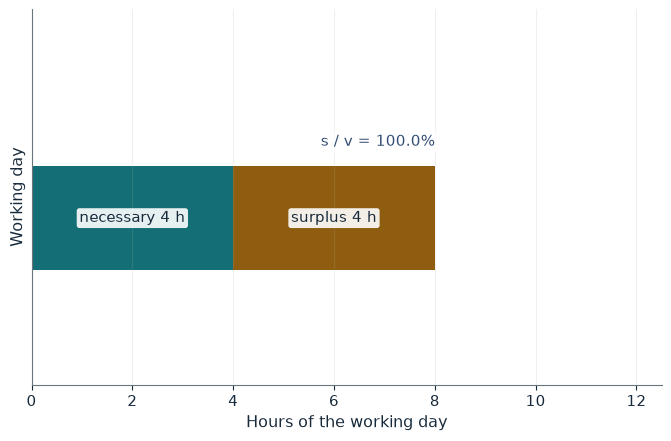

Necessary hours h          4
Wage v ($)                 120
Surplus s ($)              120
Rate s / v                 100.0%
Batch value c + v + s ($)  540

Worked steps:
  1. h = 120 / 30 = 4 hours
  2. s = 30 x (8 - 4) = 120
  3. s / v = 120 / 120 = 100.0%
  4. Batch value = 300 + 240 = 540

Hypothetical value accounting, not estimates. At $30 of new value an hour, the 120 dollar wage is reproduced in 4 hours. The remaining 4 hours create surplus of 120, so s / v = 120 / 120 = 100.0%. A longer day raises absolute surplus; a cheaper wage bundle raises relative surplus.


In [2]:
show(surplus_picture(day=8, wage=120))

Change one input, `day`, and hold the others at the book's values:

In [3]:
sweep(surplus_picture, 'day', [8, 10, 12], {'wage': 120}, ['Surplus s ($)', 'Rate s / v'])

day | Surplus s ($) | Rate s / v
8 | 120 | 100.0%
10 | 180 | 150.0%
12 | 240 | 200.0%


Four hours reproduce the wage, so an 8 hour day gives s / v = 100%; 10 hours give 150%. A \$90 wage bundle cuts necessary labor to 3 hours and raises the rate to 166.7%.

## 2. Sraffian wage-profit frontier: the one-good economy

Hypothetical: 100 grain from 50 grain and 100 hours.

$$p=(1+r)pA+wl, \qquad 100=(1+r)50+100w_g$$

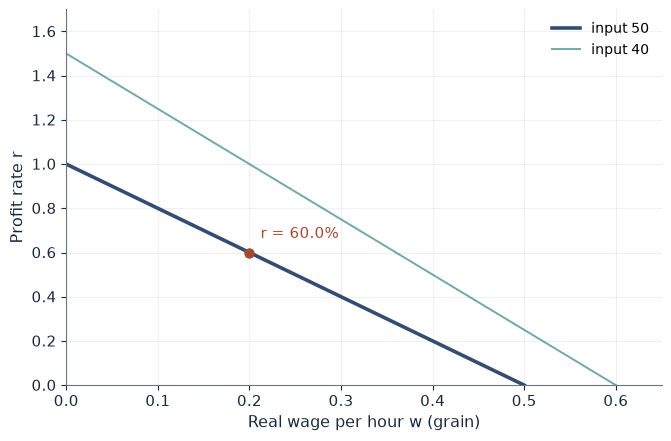

Wage bill       20.00
Profit          30.00
Profit rate r   60.0%
Maximum rate R  100.0%

Worked steps:
  1. Wages = 100 x 0.20 = 20.00
  2. Profit = 100 - 50 - 20.00 = 30.00
  3. r = 30.00 / 50 = 60.0%

Hypothetical value accounting, not estimates. With 50 grain advanced and a wage of 0.20, profit is 100 - 50 - 20.00 = 30.00 and r = 60.0%. A higher wage moves along the frontier; a smaller input shifts the whole frontier out.


In [4]:
show(frontier_picture(w=0.20, inp=50))

Change one input, `w`, and hold the others at the book's values:

In [5]:
sweep(frontier_picture, 'w', [0, 0.2, 0.35, 0.5], {'inp': 50}, ['Profit rate r'])

w | Profit rate r
0 | 100.0%
0.2 | 60.0%
0.35 | 30.0%
0.5 | 0.0%


The profit rate falls from 100% at a zero wage to 0 at 0.50. With input 40 the frontier shifts out: at w = 0.35, r = 62.5%.

## 3. Unequal exchange: production prices with a wage gap

Hypothetical: c = 40 in both sectors, new value 50, wage bills 10 (L) and 30 (H).

$$p_i=c_i+v_i+rK_i$$

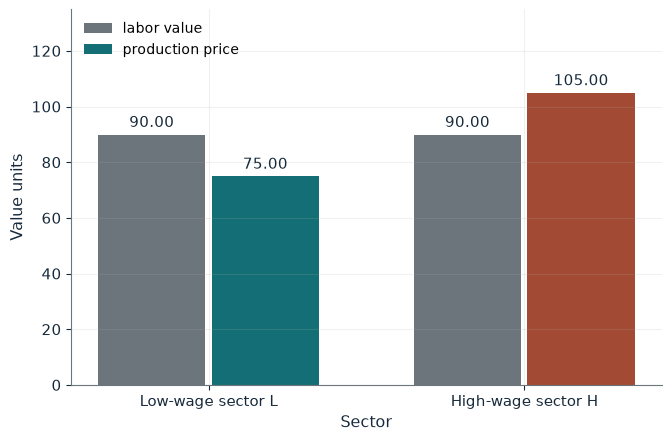

Common profit rate r      50.0%
Price p_L                 75.00
Price p_H                 105.00
Exchange ratio p_H / p_L  1.400

Worked steps:
  1. s_L = 50 - 10 = 40; s_H = 50 - 30 = 20
  2. r = (40 + 20) / (50 + 70) = 60 / 120 = 0.5000
  3. p_L = 50 x 1.5000 = 75.00; p_H = 70 x 1.5000 = 105.00
  4. Ratio = 105.00 / 75.00 = 1.400

Hypothetical value accounting, not estimates. With L's wage bill at 10, the common rate is 60 / 120 = 50.0%. Prices are 75.00 and 105.00: L sells 15.00 below its value and H 15.00 above, so one unit of H buys 1.400 units of L.


In [6]:
show(exchange_picture(vl=10))

Change one input, `vl`, and hold the others at the book's values:

In [7]:
sweep(exchange_picture, 'vl', [10, 20, 30], {}, ['Common profit rate r', 'Exchange ratio p_H / p_L'])

vl | Common profit rate r | Exchange ratio p_H / p_L
10 | 50.0% | 1.400
20 | 38.5% | 1.167
30 | 28.6% | 1.000


At a 50% common rate, prices are 75 and 105, so one unit of H trades for 1.4 of L. Equal wages remove the gap: both prices are 90.

## 4. Tendency of the rate of profit to fall: composition and exploitation

Hypothetical firm: baseline c = 80, v = 20, s = 20; after automation v = 15.

$$r=\frac{s}{c+v}=\frac{s/v}{c/v+1}$$

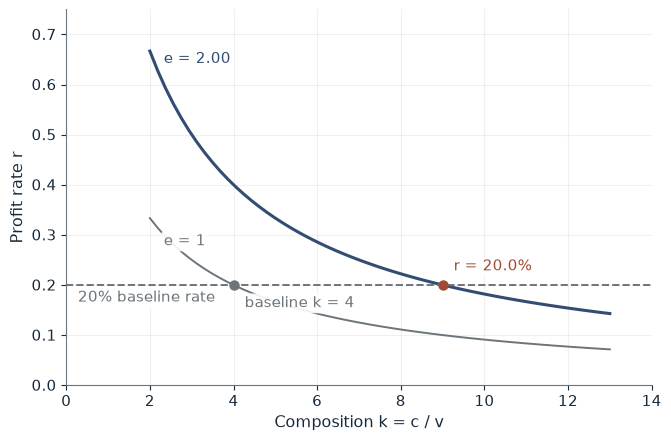

Composition k   9.00
Exploitation e  2.00
Profit rate r   20.0%

Worked steps:
  1. k = 135 / 15 = 9.00; e = 30 / 15 = 2.00
  2. r = 30 / (135 + 15) = 30 / 150 = 20.0%
  3. Check: e / (k + 1) = 2.00 / 10.00 = 20.0%

Hypothetical value accounting, not estimates. After automation, k = 9.00 and e = 2.00, so r = 30 / 150 = 20.0%, equal to the 20% baseline. The rate falls only if composition rises faster than exploitation.


In [8]:
show(composition_picture(c=135, s=30))

Change one input, `c`, and hold the others at the book's values:

In [9]:
sweep(composition_picture, 'c', [105, 135, 165], {'s': 30}, ['Composition k', 'Profit rate r'])

c | Composition k | Profit rate r
105 | 7.00 | 25.0%
135 | 9.00 | 20.0%
165 | 11.00 | 16.7%


With s = 30, k = 9 and e = 2 keep r at 20%. Surplus of 24 drops it to 16%; cheaper machinery (c = 105) lifts it to 25%.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

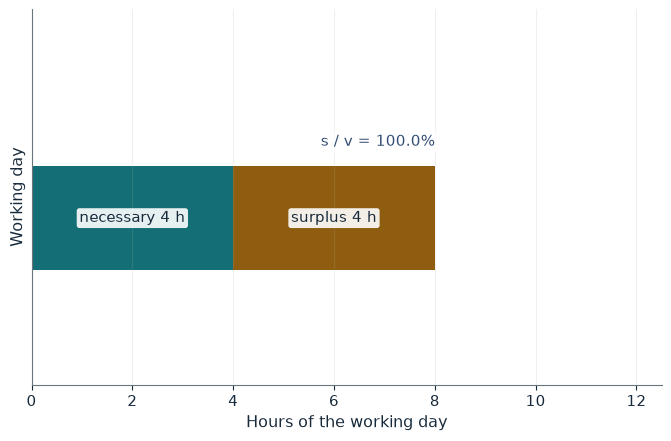

Necessary hours h          4
Wage v ($)                 120
Surplus s ($)              120
Rate s / v                 100.0%
Batch value c + v + s ($)  540

Worked steps:
  1. h = 120 / 30 = 4 hours
  2. s = 30 x (8 - 4) = 120
  3. s / v = 120 / 120 = 100.0%
  4. Batch value = 300 + 240 = 540

Hypothetical value accounting, not estimates. At $30 of new value an hour, the 120 dollar wage is reproduced in 4 hours. The remaining 4 hours create surplus of 120, so s / v = 120 / 120 = 100.0%. A longer day raises absolute surplus; a cheaper wage bundle raises relative surplus.


In [10]:
show(surplus_picture(day=8, wage=120))

## Practice

**1.** With a 12 hour day and a \$90 wage, what is s / v?

<details><summary>Answer</summary>

h = 3, s = 30 x 9 = 270, so s / v = 300%.

</details>

**2.** With input 40 and wage 0.50, what is r?

<details><summary>Answer</summary>

Profit = 100 - 40 - 50 = 10, so r = 10 / 40 = 25%.

</details>

**3.** With c = 165 and s = 30 (v = 15), what is r?

<details><summary>Answer</summary>

30 / 180 = 16.7%.

</details>